In [2]:
import tensorflow as tf
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt

Datasets that come with Keras
Keras gives you a few small datasets for practice. They download once, then stay on your computer.

Dataset	What it is
mnist	handwritten digits 0 to 9
fashion_mnist	clothing photos, 10 types
cifar10	small colour photos, 10 types
imdb	movie reviews, good or bad
We will use Fashion MNIST. It is more interesting than digits and still easy.

In [4]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 6us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 51s 2us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 8s 2us/step


In [5]:
print(x_train.shape , x_test.shape , "             " , y_train.shape , y_test.shape)

(60000, 28, 28) (10000, 28, 28)               (60000,) (10000,)


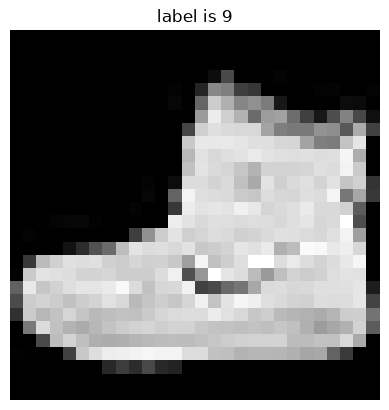

In [6]:
plt.imshow(x_train[0], cmap="gray")
plt.title("label is " + str(y_train[0]))
plt.axis("off")
plt.show()

In [7]:
class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "coat", "sandal","shirt","sneaker","bag", "ankle boot"]

print("first image is a: ", class_names[y_train[0]])

first image is a:  ankle boot


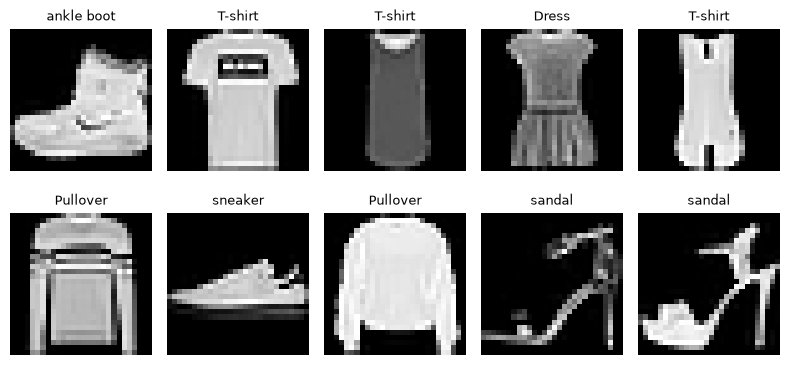

In [8]:
plt.figure(figsize=(8,4))#8 wide,4tall
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i],cmap="grey")
    plt.title(class_names[y_train[i]],fontsize = 9)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [10]:
x_train = x_train/255.0
x_test = x_test/255.0

print(x_train.min(),"=====",x_test.max())

0.0 ===== 0.00392156862745098


In [12]:
train_ds = tf.data.Dataset.from_tensor_slices((x_train,y_train))
train_ds = train_ds.shuffle(10000).batch(32).prefetch(tf.data.AUTOTUNE)

train_ds = tf.data.Dataset.from_tensor_slices((x_train,y_train))
train_ds = train_ds.batch(32).prefetch(tf.data.AUTOTUNE)

for images,lables in train_ds.take(1):
    print(images.shape)
    print(lables.shape)



(32, 28, 28)
(32,)


In [14]:
import pandas as pd

In [15]:
sample  = pd.DataFrame({
    "size_sqrt" : [800,1200, 1500, 2000, 2500],
    "bedroom" : [1,2,3,3,4],
    "price" : [50,60,55,70,80]
})

sample.to_csv('house.csv', index=False)

print("dataset saved")

dataset saved


In [16]:
data = pd.read_csv('house.csv')
data

,size_sqrt,bedroom,price
0,800,1,50
1,1200,2,60
2,1500,3,55
3,2000,3,70
4,2500,4,80


In [17]:
data.shape

(5, 3)

In [18]:
features = data[['size_sqrt','bedroom']].values
lables = data["price"].values

In [20]:
csv_ds = tf.data.Dataset.from_tensor_slices((features,lables))
csv_ds = csv_ds.batch(2)

In [23]:
for x,y in csv_ds:
    print("X:",x.numpy())
    print("Y:",y.numpy())

X: [[ 800    1]
 [1200    2]]
Y: [50 60]
X: [[1500    3]
 [2000    3]]
Y: [55 70]
X: [[2500    4]]
Y: [80]


In [ ]:
train_images = keras.utils.image_dataset_from_directory(
    "my_photos",
    image_size = (180,180),
    batch_size = 32
)